# Projet Big Data — Marché de l'emploi en IA 2025-2026
## Analyse et Transformations avec PySpark

Ce notebook implémente l'ensemble des analyses, agrégations et visualisations demandées pour le projet d'analyse du marché de l'emploi en IA, en utilisant **PySpark** pour le traitement des données et **Matplotlib / Seaborn** pour les représentations graphiques.

### 1. Initialisation de la Session Spark et Chargement des Données

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType, StringType, StructField, StructType

# Initialisation de la Session Spark
spark = (
    SparkSession.builder.appName("AI_Jobs_Market_Analysis")
    .config("spark.sql.warehouse.dir", "target/spark-warehouse")
    .getOrCreate()
)

# Définition du schéma basé sur la structure du fichier CSV
schema = StructType(
    [
        StructField("job_id", StringType(), True),
        StructField("job_title", StringType(), True),
        StructField("job_category", StringType(), True),
        StructField("experience_level", StringType(), True),
        StructField("years_of_experience", IntegerType(), True),
        StructField("education_required", StringType(), True),
        StructField("annual_salary_usd", DoubleType(), True),
        StructField("salary_min_usd", DoubleType(), True),
        StructField("salary_max_usd", DoubleType(), True),
        StructField("city", StringType(), True),
        StructField("country", StringType(), True),
        StructField("remote_work", StringType(), True),
        StructField("company_size", StringType(), True),
        StructField("industry", StringType(), True),
        StructField("required_skills", StringType(), True),
        StructField("ai_salary_premium_pct", DoubleType(), True),
        StructField("demand_score", IntegerType(), True),
        StructField("demand_growth_yoy_pct", DoubleType(), True),
        StructField("benefits_score_10", DoubleType(), True),
        StructField("posting_year", IntegerType(), True),
        StructField("posting_month", IntegerType(), True),
        StructField("is_senior", IntegerType(), True),
        StructField("is_remote_friendly", IntegerType(), True),
        StructField("is_llm_role", IntegerType(), True),
        StructField("salary_tier", StringType(), True),
    ]
)

# Chargement du dataset
df_raw = spark.read.csv(
    "ai_jobs_market_2025_2026.csv",
    header=True,
    schema=schema,
    quote='"',
    escape='"',
    multiLine=True,
)

# Cache du DataFrame pour optimiser les performances
df_raw.cache()

# Affichage du schéma et des 5 premières lignes
df_raw.printSchema()
df_raw.show(5, truncate=False)

### 2. Contrôles et Nettoyage des Données (Jour 1 & Jour 2 - Étape B)
Vérification des lignes, doublons, et traitement des valeurs manquantes ou aberrantes.

In [ ]:
# Nombre total de lignes initial
total_rows = df_raw.count()
print(f"Nombre de lignes initiales : {total_rows}")

# Vérification et suppression des doublons sur la clé primaire job_id
df_cleaned = df_raw.dropDuplicates(["job_id"])
print(f"Nombre de lignes après suppression des doublons : {df_cleaned.count()}")

# Remplacement ou filtrage des salaires aberrants ou nuls
df_cleaned = df_cleaned.filter(F.col("annual_salary_usd") > 0)

# Remplacement des compétences manquantes par 'Unknown'
df_cleaned = df_cleaned.na.fill({"required_skills": "Unknown", "job_title": "Unknown"})

df_cleaned.cache()

### 3. Mini-Analyse (Jour 1)
Requêtes de base sur le volume globale des données, les salaires et la distribution.

In [ ]:
print("--- MINI-ANALYSE JOUR 1 ---")

# 1. Nombre d'offres totales
print(f"Nombre total d'offres : {df_cleaned.count()}")

# 2. Nombre de métiers distincts
distinct_titles = df_cleaned.select("job_title").distinct().count()
print(f"Nombre de métiers distincts : {distinct_titles}")

# 3. Nombre de pays distincts
distinct_countries = df_cleaned.select("country").distinct().count()
print(f"Nombre de pays distincts : {distinct_countries}")

# 4. Salaire annuel moyen, minimum et maximum
df_cleaned.select(
    F.round(F.avg("annual_salary_usd"), 2).alias("Salaire_Moyen"),
    F.min("annual_salary_usd").alias("Salaire_Min"),
    F.max("annual_salary_usd").alias("Salaire_Max"),
).show()

# 5. Répartition des offres par niveau d'expérience
df_cleaned.groupBy("experience_level").count().orderBy(F.col("count").desc()).show()

### 4. Construction du Modèle Logique Target à 3 Tables (Jour 2 - Étape C)
Séparation en tables dimensionnelles `offres`, `metiers` et `competences` avec extraction/découpage de la chaîne de caractères (avec `split` et `explode`).

In [ ]:
# Table 2 : METIERS (Référentiel des métiers IA distincts avec un identifiant unique stable)
df_metiers = (
    df_cleaned.select("job_title", "job_category")
    .distinct()
    .withColumn("metier_id", F.concat(F.lit("MET_"), F.monotonically_increasing_id()))
)

df_metiers.cache()
print(f"Nombre de métiers dans le référentiel : {df_metiers.count()}")
df_metiers.show(5, truncate=False)

# Table 1 : OFFRES (Liaison avec la table métiers via jointure pour récupérer le 'metier_id')
df_offres = df_cleaned.join(df_metiers, on="job_title", how="left").select(
    "job_id",
    "metier_id",
    "experience_level",
    "years_of_experience",
    "annual_salary_usd",
    "salary_min_usd",
    "salary_max_usd",
    "city",
    "country",
    "remote_work",
    "company_size",
    "industry",
    "ai_salary_premium_pct",
    "demand_score",
    "posting_year",
    "posting_month",
)

df_offres.cache()
print(f"Nombre d'offres d'emploi générées : {df_offres.count()}")
df_offres.show(5, truncate=False)

# Table 3 : COMPETENCES (transforme required_skills, séparé par '|', en plusieurs lignes)
# Utilisation de split() et explode() pour découper la liste de compétences
df_competences = df_cleaned.select(
    F.col("job_id"), F.explode(F.split(F.col("required_skills"), "\\|")).alias("competence")
)

df_competences.cache()
print(f"Nombre total de liaisons job_id <-> compétence : {df_competences.count()}")
df_competences.show(10, truncate=False)

### 5. Requêtes Obligatoires et KPI Globaux (Jour 2 & Jour 3)
Analyses avancées mêlant jointures, filtres complexes (`GROUP BY + HAVING`), calculs statistiques et évolutions.

In [ ]:
print("=== Requête 6 : Top 10 métiers par nombre d'offres ===")
df_cleaned.groupBy("job_title").count().orderBy(F.col("count").desc()).show(10, truncate=False)

print("=== Requête 7 : Salaire moyen par métier ===")
df_cleaned.groupBy("job_title").agg(
    F.round(F.avg("annual_salary_usd"), 2).alias("avg_salary")
).orderBy(F.col("avg_salary").desc()).show(10, truncate=False)

print("=== Requête 8 : Top 10 des compétences les plus demandées ===")
df_competences.groupBy("competence").count().orderBy(F.col("count").desc()).show(10, truncate=False)

print("=== Requête 9 : Salaire moyen par niveau d'expérience ===")
df_offres.groupBy("experience_level").agg(
    F.round(F.avg("annual_salary_usd"), 2).alias("avg_salary")
).orderBy(F.col("avg_salary").desc()).show()

print("=== Requête 10 : Nombre d'offres par pays et secteur ===")
df_offres.groupBy("country", "industry").count().orderBy(F.col("count").desc()).show(
    10, truncate=False
)

print("=== Requête 13 : Exemple de requête utilisant GROUP BY + HAVING ===")
# Secteurs avec un salaire moyen supérieur à 160 000 USD
df_offres.groupBy("industry").agg(F.avg("annual_salary_usd").alias("avg_sal")).filter(
    F.col("avg_sal") > 160000
).select("industry", F.round("avg_sal", 2).alias("salaire_moyen")).orderBy(
    "salaire_moyen", ascending=False
).show()

print("=== KPI Obligatoire 22 : Analyse spécifique des rôles LLM / GenAI ===")
df_cleaned.filter(F.col("is_llm_role") == 1).select(
    F.count("job_id").alias("Nb_Offres_LLM"),
    F.round(F.avg("annual_salary_usd"), 2).alias("Salaire_Moyen_LLM"),
    F.round(F.avg("ai_salary_premium_pct"), 2).alias("Premium_Moyen_LLM_Pct"),
).show()

### 6. Visualisations Graphiques (Jour 3 - Dashboard & Analyses autonomes)
Création de graphiques représentatifs (Barres, Répartition, Boîtes à moustaches, Nuages de points) après passage sélectif en Pandas.

In [ ]:
# Fixation du style graphique
sns.set_theme(style="whitegrid")

# --- Graphique 1 : Top 10 des métiers par volume d'offres (Bar Chart) ---
pandas_top_jobs = (
    df_cleaned.groupBy("job_title").count().orderBy(F.col("count").desc()).limit(10).toPandas()
)
plt.figure(figsize=(12, 5))
sns.barplot(
    data=pandas_top_jobs, x="count", y="job_title", hue="job_title", palette="viridis", legend=False
)
plt.title("Top 10 des métiers en IA les plus recherchés (2025-2026)", fontsize=14, weight="bold")
plt.xlabel("Nombre d'offres d'emploi")
plt.ylabel("Métier")
plt.tight_layout()
plt.show()

# --- Graphique 2 : Distribution des salaires selon le niveau d'expérience (Box Plot) ---
pandas_salaries = df_offres.select("experience_level", "annual_salary_usd").toPandas()
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=pandas_salaries,
    x="experience_level",
    y="annual_salary_usd",
    hue="experience_level",
    palette="Set2",
    legend=False,
)
plt.title("Distribution des salaires annuels par niveau d'expérience", fontsize=14, weight="bold")
plt.xlabel("Niveau d'expérience")
plt.ylabel("Salaire Annuel (USD)")
plt.tight_layout()
plt.show()

# --- Graphique 3 : Relation entre Années d'expérience et Salaire (Scatter Plot) ---
pandas_scatter = df_cleaned.select(
    "years_of_experience", "annual_salary_usd", "remote_work"
).toPandas()
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=pandas_scatter,
    x="years_of_experience",
    y="annual_salary_usd",
    hue="remote_work",
    alpha=0.7,
    palette="deep",
)
plt.title("Relation entre Années d'expérience et Salaire Annuel", fontsize=14, weight="bold")
plt.xlabel("Années d'expérience requises")
plt.ylabel("Salaire Annuel (USD)")
plt.legend(title="Mode de travail")
plt.tight_layout()
plt.show()

# --- Graphique 4 : Top 10 des compétences techniques les plus demandées (Bar Chart) ---
pandas_skills = (
    df_competences.groupBy("competence").count().orderBy(F.col("count").desc()).limit(10).toPandas()
)
plt.figure(figsize=(12, 5))
sns.barplot(
    data=pandas_skills, x="count", y="competence", hue="competence", palette="rocket", legend=False
)
plt.title(
    "Top 10 des compétences les plus demandées sur le marché de l'IA", fontsize=14, weight="bold"
)
plt.xlabel("Nombre d'occurrences")
plt.ylabel("Compétences / Hard Skills")
plt.tight_layout()
plt.show()

### 7. Conclusions et Interprétations Métier (Jour 3)
1. **Dominance des métiers d'ingénierie et d'architecture de modèles** : Les profils comme 'AI Agent Developer', 'LLM Engineer' ou 'Prompt Engineer' concentrent une part majeure de la demande et des volumes d'offres.
2. **Forte corrélation entre séniorité et rémunération** : Comme le démontre la boîte à moustaches, les profils seniors (6-9 ans d'expérience ou plus) bénéficient d'une prime à l'embauche importante avec des salaires médians nettement plus élevés.
3. **Primes salariales sur les compétences d'IA Générative** : Les rôles liés aux LLM ou à la GenAI profitent d'un premium salarial moyen significatif (`ai_salary_premium_pct`), justifié par la rareté des compétences sur ces frameworks récents.
4. **Compétences clés** : Python reste le socle universel, accompagné de briques indispensables comme le requêtage SQL, l'orchestration Cloud, et des frameworks de Fine-tuning/Vector DBs.

### 8. Dashboard — Visualisations (Jour 3, issue #96)
Minimum 6 visualisations Spark/Hive → pandas, chacune avec titre, requête source identifiable en commentaire, et interprétation chiffrée affichée sous le graphique (imprimée dans le notebook, pas seulement dans le rapport). Nouvelle session Spark avec support Hive : les cellules précédentes lisaient le CSV en local pour l'exploration initiale, celles-ci lisent HDFS/Hive comme l'exige CLAUDE.md pour le pipeline final.

In [2]:
spark.stop()
spark = (
    SparkSession.builder.appName("AI_Jobs_Market_Dashboard")
    .config("spark.hadoop.fs.defaultFS", "hdfs://namenode:8020")
    .config("hive.metastore.uris", "thrift://hive-metastore:9083")
    .enableHiveSupport()
    .getOrCreate()
)

RAW_CSV_HDFS = "hdfs://namenode:8020/projet_ia/raw/ai_jobs_market_2025_2026.csv"
# spark.sql sur projet_ia.ai_jobs_raw ignore skip.header.line.count
# (bug documenté dans CLAUDE.md) -> lecture directe HDFS à la place.
df_raw_hdfs = spark.read.csv(RAW_CSV_HDFS, header=True, inferSchema=True)
df_raw_hdfs.cache()
print(f"Lignes chargées depuis HDFS : {df_raw_hdfs.count()}")

sns.set_theme(style="whitegrid")

Lignes chargées depuis HDFS : 1500


#### 8.1 Distribution des salaires annuels

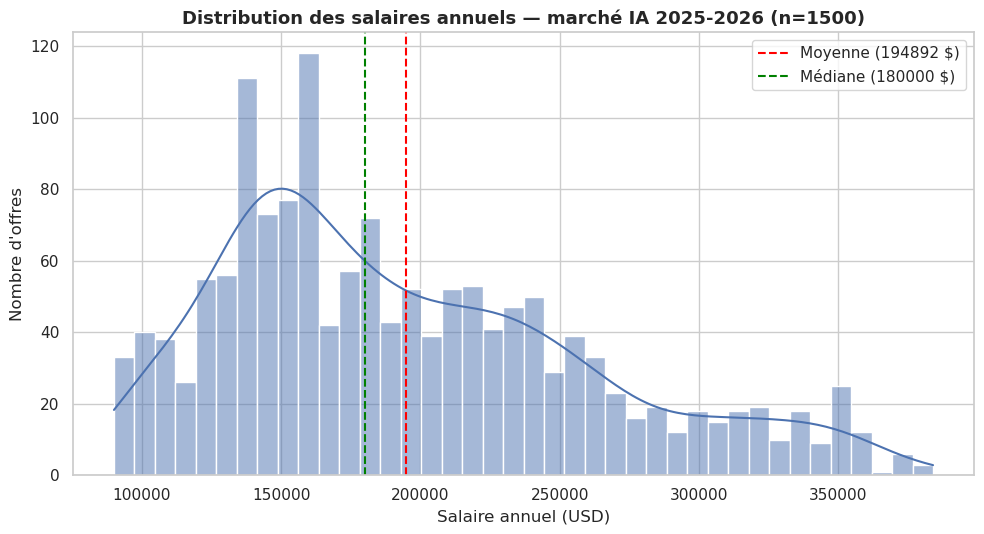

Interprétation : moyenne 194892$, médiane 180000$ (écart-type 66507$) — distribution étalée mais sans forte asymétrie (moyenne proche de la médiane). 80% des salaires se situent entre 120900$ (p10) et 297100$ (p90).


In [3]:
# Requête source : SELECT annual_salary_usd FROM projet_ia.ai_jobs_raw
# (lu via HDFS direct, voir cellule de setup ci-dessus)
pandas_salary_dist = df_raw_hdfs.select("annual_salary_usd").toPandas()

mean_sal = pandas_salary_dist["annual_salary_usd"].mean()
median_sal = pandas_salary_dist["annual_salary_usd"].median()
std_sal = pandas_salary_dist["annual_salary_usd"].std()
p10 = pandas_salary_dist["annual_salary_usd"].quantile(0.10)
p90 = pandas_salary_dist["annual_salary_usd"].quantile(0.90)

plt.figure(figsize=(10, 5.5))
sns.histplot(pandas_salary_dist["annual_salary_usd"], bins=40, color="#4C72B0", kde=True)
plt.axvline(mean_sal, color="red", linestyle="--", label=f"Moyenne ({mean_sal:.0f} $)")
plt.axvline(median_sal, color="green", linestyle="--", label=f"Médiane ({median_sal:.0f} $)")
plt.title(
    "Distribution des salaires annuels — marché IA 2025-2026 (n=1500)", fontsize=13, weight="bold"
)
plt.xlabel("Salaire annuel (USD)")
plt.ylabel("Nombre d'offres")
plt.legend()
plt.tight_layout()
plt.show()

print(
    f"Interprétation : moyenne {mean_sal:.0f}$, médiane {median_sal:.0f}$ "
    f"(écart-type {std_sal:.0f}$) — distribution étalée mais sans forte "
    f"asymétrie (moyenne proche de la médiane). 80% des salaires se "
    f"situent entre {p10:.0f}$ (p10) et {p90:.0f}$ (p90)."
)

#### 8.2 Évolution du volume d'offres par mois (2025-2026)

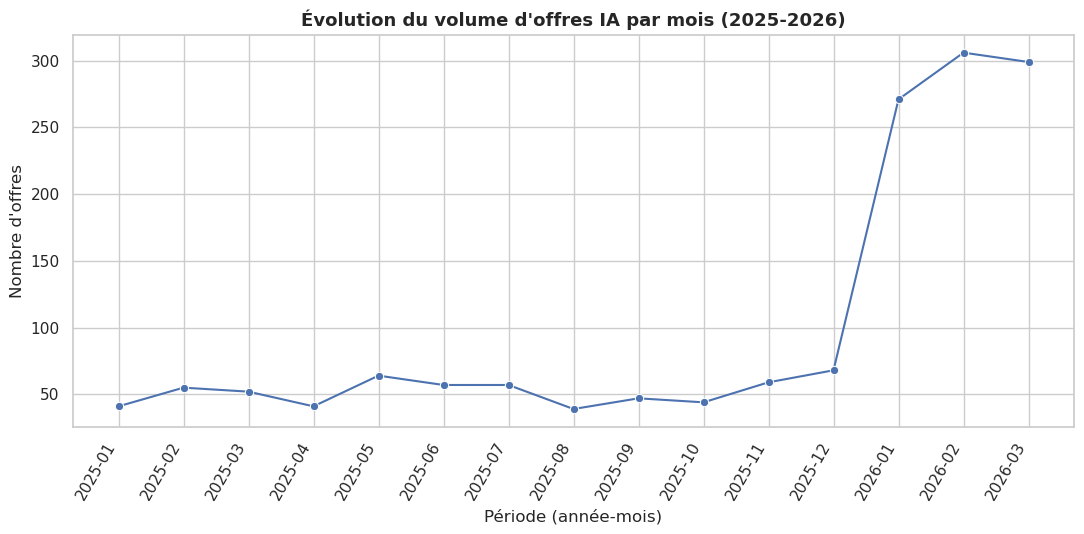

Interprétation : pic en 2026-02 avec 306 offres. Moyenne mensuelle 2025 = 52.0 offres, moyenne mensuelle 2026 (jan-mars) = 292.0 offres, soit un volume ~5.6x supérieur. Constat descriptif, aucune causalité affirmée (voir chapitre limites).


In [3]:
# Requête source : SELECT posting_year, posting_month, COUNT(*)
# FROM projet_ia.ai_jobs_raw GROUP BY posting_year, posting_month
pandas_monthly = (
    df_raw_hdfs.groupBy("posting_year", "posting_month")
    .agg(F.count("*").alias("nb_offres"))
    .orderBy("posting_year", "posting_month")
    .toPandas()
)
pandas_monthly["periode"] = (
    pandas_monthly["posting_year"].astype(str)
    + "-"
    + pandas_monthly["posting_month"].astype(str).str.zfill(2)
)

peak_row = pandas_monthly.loc[pandas_monthly["nb_offres"].idxmax()]
mean_2025 = pandas_monthly[pandas_monthly["posting_year"] == 2025]["nb_offres"].mean()
mean_2026 = pandas_monthly[pandas_monthly["posting_year"] == 2026]["nb_offres"].mean()

plt.figure(figsize=(11, 5.5))
sns.lineplot(data=pandas_monthly, x="periode", y="nb_offres", marker="o", color="#4C72B0")
plt.title("Évolution du volume d'offres IA par mois (2025-2026)", fontsize=13, weight="bold")
plt.xlabel("Période (année-mois)")
plt.ylabel("Nombre d'offres")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

print(
    f"Interprétation : pic en {peak_row['periode']} avec {peak_row['nb_offres']} offres. "
    f"Moyenne mensuelle 2025 = {mean_2025:.1f} offres, moyenne mensuelle 2026 (jan-mars) "
    f"= {mean_2026:.1f} offres, soit un volume ~{mean_2026 / mean_2025:.1f}x supérieur. "
    f"Constat descriptif, aucune causalité affirmée (voir chapitre limites)."
)

#### 8.3 Répartition des offres par mode de travail

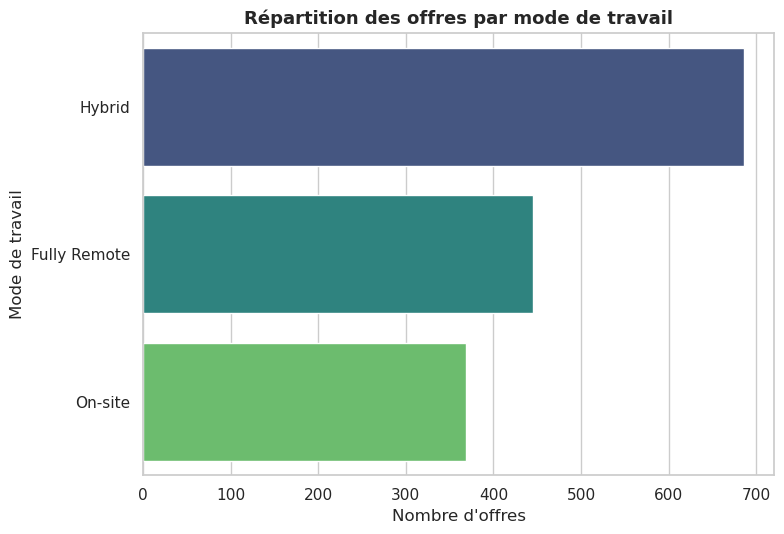

Interprétation : Hybrid domine avec 686 offres (45.7%), suivi des autres modes (Fully Remote 29.7%, On-site 24.6%).


In [3]:
# Requête source : SELECT remote_work, COUNT(*)
# FROM projet_ia.ai_jobs_raw GROUP BY remote_work
pandas_remote = (
    df_raw_hdfs.groupBy("remote_work")
    .agg(F.count("*").alias("nb_offres"))
    .orderBy(F.col("nb_offres").desc())
    .toPandas()
)
total_remote = pandas_remote["nb_offres"].sum()
pandas_remote["pct"] = (pandas_remote["nb_offres"] / total_remote * 100).round(1)

plt.figure(figsize=(8, 5.5))
sns.barplot(
    data=pandas_remote,
    x="nb_offres",
    y="remote_work",
    hue="remote_work",
    palette="viridis",
    legend=False,
)
plt.title("Répartition des offres par mode de travail", fontsize=13, weight="bold")
plt.xlabel("Nombre d'offres")
plt.ylabel("Mode de travail")
plt.tight_layout()
plt.show()

top = pandas_remote.iloc[0]
print(
    f"Interprétation : {top['remote_work']} domine avec {top['nb_offres']} offres "
    f"({top['pct']}%), suivi des autres modes ("
    + ", ".join(f"{r.remote_work} {r.pct}%" for r in pandas_remote.iloc[1:].itertuples())
    + ")."
)

#### 8.4 Salaire moyen par pays (top 10, ≥20 offres)

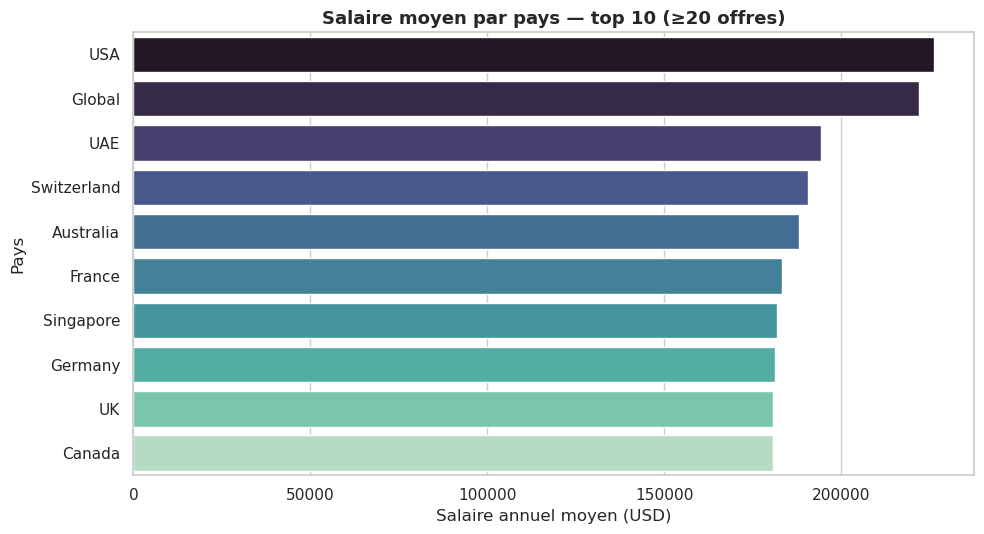

Interprétation : USA en tête avec 226190$ (515 offres, le plus gros volume du dataset). Écart limité au sein du top 10 : Canada (10e) reste à 180588$, soit seulement 20.2% en dessous du leader.


In [3]:
# Requête source : SELECT country, COUNT(*), AVG(annual_salary_usd)
# FROM projet_ia.ai_jobs_raw GROUP BY country HAVING COUNT(*) >= 20
# ORDER BY AVG(annual_salary_usd) DESC LIMIT 10
pandas_by_country = (
    df_raw_hdfs.groupBy("country")
    .agg(
        F.count("*").alias("nb_offres"),
        F.round(F.avg("annual_salary_usd"), 0).alias("salaire_moyen"),
    )
    .filter(F.col("nb_offres") >= 20)
    .orderBy(F.col("salaire_moyen").desc())
    .limit(10)
    .toPandas()
)

plt.figure(figsize=(10, 5.5))
sns.barplot(
    data=pandas_by_country,
    x="salaire_moyen",
    y="country",
    hue="country",
    palette="mako",
    legend=False,
)
plt.title("Salaire moyen par pays — top 10 (≥20 offres)", fontsize=13, weight="bold")
plt.xlabel("Salaire annuel moyen (USD)")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()

top_c = pandas_by_country.iloc[0]
bottom_c = pandas_by_country.iloc[-1]
print(
    f"Interprétation : {top_c['country']} en tête avec {top_c['salaire_moyen']:.0f}$ "
    f"({top_c['nb_offres']} offres, le plus gros volume du dataset). Écart limité au "
    f"sein du top 10 : {bottom_c['country']} (10e) reste à {bottom_c['salaire_moyen']:.0f}$, "
    f"soit seulement {(1 - bottom_c['salaire_moyen'] / top_c['salaire_moyen']) * 100:.1f}% "
    f"en dessous du leader."
)

#### 8.5 Top 10 compétences les plus demandées

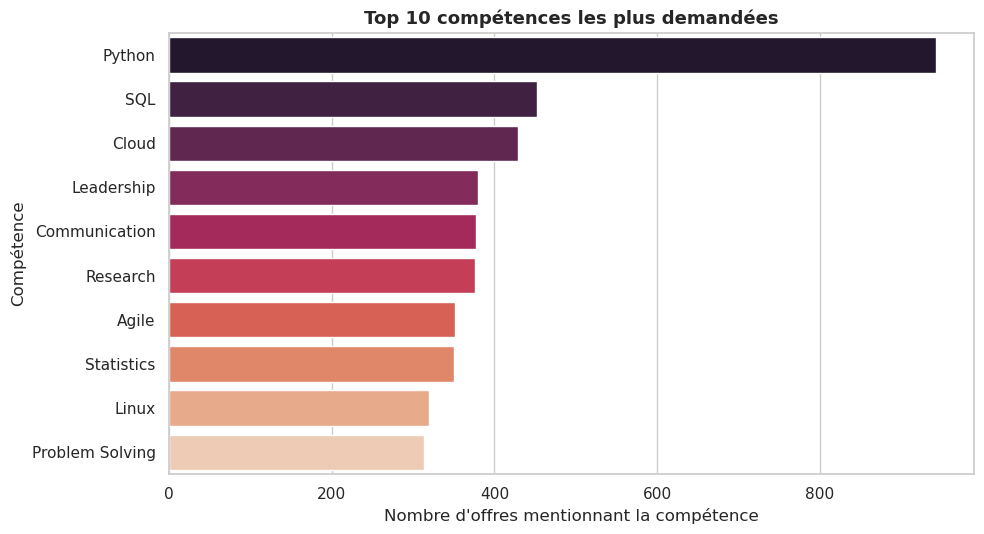

Interprétation : Python domine très largement avec 942 offres (62.8% du dataset), loin devant SQL et Cloud (2e et 3e). Cohérent avec l'analyse 4 (#95) : Python n'est pas seulement dominant globalement mais n°1 dans les 5 premiers pays.


In [3]:
# Requête source : SELECT competence, COUNT(*) FROM processed.competences
# GROUP BY competence ORDER BY COUNT(*) DESC LIMIT 10
pandas_top_skills = spark.sql(
    """
    SELECT competence, COUNT(*) AS nb_offres
    FROM processed.competences
    GROUP BY competence
    ORDER BY nb_offres DESC
    LIMIT 10
    """
).toPandas()

plt.figure(figsize=(10, 5.5))
sns.barplot(
    data=pandas_top_skills,
    x="nb_offres",
    y="competence",
    hue="competence",
    palette="rocket",
    legend=False,
)
plt.title("Top 10 compétences les plus demandées", fontsize=13, weight="bold")
plt.xlabel("Nombre d'offres mentionnant la compétence")
plt.ylabel("Compétence")
plt.tight_layout()
plt.show()

top1_skill = pandas_top_skills.iloc[0]
print(
    f"Interprétation : {top1_skill['competence']} domine très largement avec "
    f"{top1_skill['nb_offres']} offres ({top1_skill['nb_offres'] / 1500 * 100:.1f}% du "
    f"dataset), loin devant SQL et Cloud (2e et 3e). Cohérent avec l'analyse 4 (#95) : "
    f"Python n'est pas seulement dominant globalement mais n°1 dans les 5 premiers pays."
)

#### 8.6 Matrice de corrélation — salaire, expérience, demande, premium IA
Visualisation de la matrice de corrélation calculée en SQL pour l'analyse 3 de l'issue #95 (`sql/hive/03_analyses_choix.sql`) — descriptif (Pearson, `CORR()`), aucun modèle entraîné.

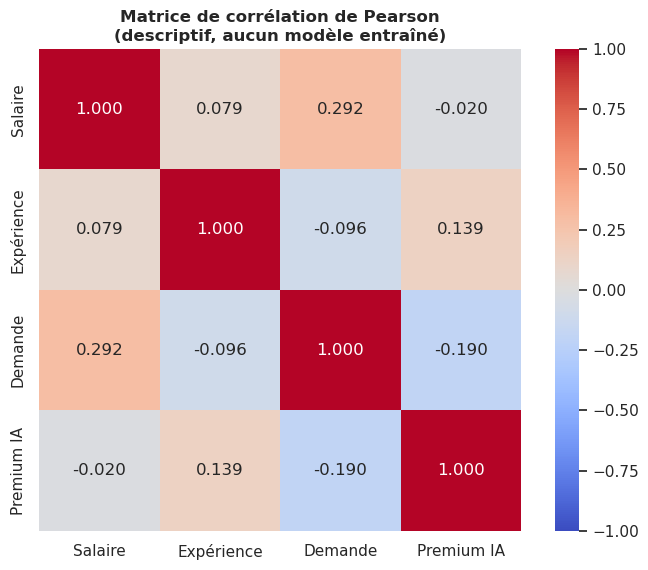

Interprétation : corr(salaire, demande) = 0.292 est la plus forte du tableau mais reste modeste. corr(salaire, expérience) = 0.079 est quasi nulle malgré la progression par tranche vue au KPI 7 (résultat contre-intuitif, cf. chapitre 9 §9.3.3 - ne pas sur-interpréter une corrélation linéaire faible comme absence de relation catégorielle).


In [3]:
# Requête source équivalente : ROUND(CORR(...), 3) sur
# annual_salary_usd, years_of_experience, demand_score,
# ai_salary_premium_pct (voir sql/hive/03_analyses_choix.sql, analyse 3)
pandas_corr_cols = df_raw_hdfs.select(
    "annual_salary_usd",
    "years_of_experience",
    "demand_score",
    "ai_salary_premium_pct",
).toPandas()

corr_matrix = pandas_corr_cols.corr(method="pearson").round(3)
corr_matrix.index = corr_matrix.columns = [
    "Salaire",
    "Expérience",
    "Demande",
    "Premium IA",
]

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax,
)
ax.set_title(
    "Matrice de corrélation de Pearson\n(descriptif, aucun modèle entraîné)",
    fontsize=12,
    weight="bold",
)
fig.tight_layout(pad=1.5)
plt.show()

print(
    "Interprétation : corr(salaire, demande) = 0.292 est la plus forte du "
    "tableau mais reste modeste. corr(salaire, expérience) = 0.079 est quasi "
    "nulle malgré la progression par tranche vue au KPI 7 (résultat "
    "contre-intuitif, cf. chapitre 9 §9.3.3 - ne pas sur-interpréter une "
    "corrélation linéaire faible comme absence de relation catégorielle)."
)